# Artificial Intelligence
인공지능

## Study Hours and Exam Score Prediction
공부 시간에 따른 시험 점수 예측

### Simple Linear Regression
단순 선형 회귀

**Learning objective:** Predict exam scores from study hours and evaluate the model on unseen data.  
**학습 목표:** 공부 시간으로 시험 점수를 예측하고 처음 보는 데이터에서 모델을 평가합니다.

**Data notice:** This project uses 100 synthetic student records for practice, not real survey data.  
**데이터 안내:** 실제 조사 자료가 아닌 실습용 가상 학생 데이터 100개를 사용합니다.

The results do not establish real-world predictive performance or a causal effect of studying.  
결과는 실제 학생 대상 예측 성능이나 공부의 인과적 효과를 입증하지 않습니다.

**Roadmap:** Load data → Check quality → Split data → Explore → Train → Evaluate → Predict.  
**진행 순서:** 데이터 불러오기 → 품질 확인 → 데이터 분할 → 탐색 → 학습 → 평가 → 예측.

**How to run:** Open this notebook in Google Colab or Jupyter and run all cells from top to bottom.  
**실행 방법:** Google Colab 또는 Jupyter에서 노트북을 열고 위에서부터 모든 셀을 실행하세요.

The dataset is embedded, so no separate CSV download is required.  
데이터가 포함되어 있어 CSV 파일을 별도로 다운로드할 필요가 없습니다.

For local execution, install the packages in requirements.txt and Jupyter.  
로컬 실행에는 requirements.txt의 패키지와 Jupyter가 필요합니다.

### 1. Import libraries
1. 라이브러리 불러오기

Import the libraries for data analysis, visualization, model training, and evaluation.  
데이터 분석, 시각화, 모델 학습과 평가에 필요한 라이브러리를 불러옵니다.

In [1]:
from io import StringIO
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

RANDOM_STATE = 42
plt.rcParams['figure.figsize'] = (9, 5)


### 2. Load the dataset
2. 데이터 불러오기

Each row represents one synthetic student.  
각 행은 가상의 학생 한 명을 나타냅니다.

`study_hours` is the average daily study time during the week before the exam, measured in hours per day.  
`study_hours`는 시험 전 1주일의 하루 평균 공부 시간이며 단위는 시간/일입니다.

`exam_score` is the exam score on a scale from 0 to 100.  
`exam_score`는 0~100점 범위의 시험 점수입니다.

The data were generated by `generate_data.py` with random seed 42.  
데이터는 난수 시드 42를 사용하여 `generate_data.py`로 생성했습니다.

Scores follow `30 + 7 × study hours + random noise`, with normally distributed noise of standard deviation 7 and scores clipped to 0–100.  
점수는 `30 + 7 × 공부 시간 + 무작위 오차`로 생성했으며, 오차는 표준편차 7인 정규분포를 따르고 점수는 0~100으로 제한했습니다.

The embedded data below are identical to `study_scores.csv`.  
아래에 포함된 데이터는 `study_scores.csv`와 동일합니다.

In [2]:
CSV_DATA = 'study_hours,exam_score\n5.9,76.8\n2.4,47.7\n6.8,71.0\n1.2,25.2\n4.1,63.5\n4.8,64.5\n0.7,38.1\n5.1,75.3\n2.4,36.0\n0.6,27.4\n7.3,79.1\n1.8,36.6\n8.6,88.6\n1.3,41.7\n7.7,73.8\n6.7,69.2\n5.1,72.4\n5.2,65.3\n7.5,72.3\n5.4,58.4\n6.5,80.3\n3.0,52.4\n1.2,38.7\n2.9,53.5\n5.9,66.9\n2.3,51.2\n2.8,58.9\n5.7,66.0\n2.0,43.5\n3.7,51.8\n8.9,86.6\n6.3,67.2\n7.7,84.7\n0.8,30.6\n3.2,51.9\n8.5,94.3\n7.9,81.3\n3.9,66.7\n8.3,82.8\n2.6,49.6\n5.3,66.4\n8.1,95.9\n3.9,61.9\n4.8,87.4\n1.3,42.3\n5.8,71.6\n7.2,78.2\n3.7,57.1\n9.0,74.7\n7.8,81.2\n0.6,32.3\n5.1,55.3\n2.8,47.4\n4.2,56.8\n4.4,74.5\n2.7,44.8\n4.8,70.3\n7.9,99.2\n3.0,44.8\n1.8,35.2\n7.0,67.2\n5.0,62.0\n0.5,32.9\n8.4,90.0\n8.0,88.9\n1.0,31.8\n8.0,88.8\n4.6,61.2\n1.1,38.5\n1.6,29.3\n4.5,56.3\n7.9,83.6\n4.1,60.8\n6.7,85.4\n2.2,36.8\n6.0,93.2\n4.2,55.9\n2.4,46.4\n3.4,49.5\n2.4,44.1\n1.1,34.3\n8.2,83.7\n7.8,89.3\n6.2,75.6\n2.3,57.1\n5.4,79.9\n4.5,64.2\n2.1,32.3\n1.3,32.4\n4.5,64.6\n6.7,67.6\n1.3,21.2\n3.9,49.9\n2.6,60.0\n2.1,37.8\n2.9,52.6\n2.6,54.9\n7.8,81.1\n5.2,91.7\n7.6,91.5\n'

df = pd.read_csv(StringIO(CSV_DATA))
print("Rows and columns:", df.shape)
print("행과 열의 수:", df.shape)
display(df.head(10))

Rows and columns: (100, 2)
행과 열의 수: (100, 2)


,study_hours,exam_score
0,5.9,76.8
1,2.4,47.7
2,6.8,71.0
3,1.2,25.2
4,4.1,63.5
5,4.8,64.5
6,0.7,38.1
7,5.1,75.3
8,2.4,36.0
9,0.6,27.4


### 3. Inspect data quality
3. 데이터 품질 확인

Check for missing values, non-finite values, and values outside the valid ranges.  
결측치, 유한하지 않은 값, 유효 범위를 벗어난 값이 있는지 확인합니다.

Multiple students may have the same study time, so repeated study-hour values are not necessarily errors.  
여러 학생의 공부 시간이 같을 수 있으므로 공부 시간의 중복은 반드시 오류를 의미하지 않습니다.

In [3]:
display(df.describe())
display(df.isna().sum().to_frame('Missing values'))
assert df.shape == (100, 2)
assert df.notna().all().all()
assert np.isfinite(df.to_numpy()).all()
assert df.study_hours.between(0, 24).all()
assert df.exam_score.between(0, 100).all()
print('Data quality checks passed.')
print('데이터 품질 검사를 통과했습니다.')

,study_hours,exam_score
count,100.000000,100.000000
mean,4.540000,61.434000
std,2.474598,19.610388
min,0.500000,21.200000
25%,2.400000,46.000000
50%,4.500000,61.950000
75%,6.700000,77.150000
max,9.000000,99.200000


,Missing values
study_hours,0
exam_score,0


Data quality checks passed.
데이터 품질 검사를 통과했습니다.


### 4. Split training and test data
4. 학습용·테스트용 데이터 분할

Use 80 students for training and 20 students for final evaluation.  
80명의 데이터는 학습에, 20명의 데이터는 최종 평가에 사용합니다.

The test data are not used to fit the model.  
테스트 데이터는 모델 학습에 사용하지 않습니다.

A fixed random seed makes the split reproducible.  
고정된 난수 시드를 사용하여 같은 데이터 분할을 재현할 수 있습니다.

In [4]:
X = df[['study_hours']]
y = df['exam_score']
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE)
display(pd.DataFrame({'Subset': ['Training', 'Test'],
                      'Rows': [len(X_train), len(X_test)]}))

,Subset,Rows
0,Training,80
1,Test,20


### 5. Explore the training data
5. 학습 데이터 탐색

Each point in the scatter plot represents one synthetic student.  
산점도의 각 점은 가상의 학생 한 명을 나타냅니다.

Inspect the relationship between study hours and exam scores using the training set.  
학습 데이터를 사용하여 공부 시간과 시험 점수 사이의 관계를 살펴봅니다.

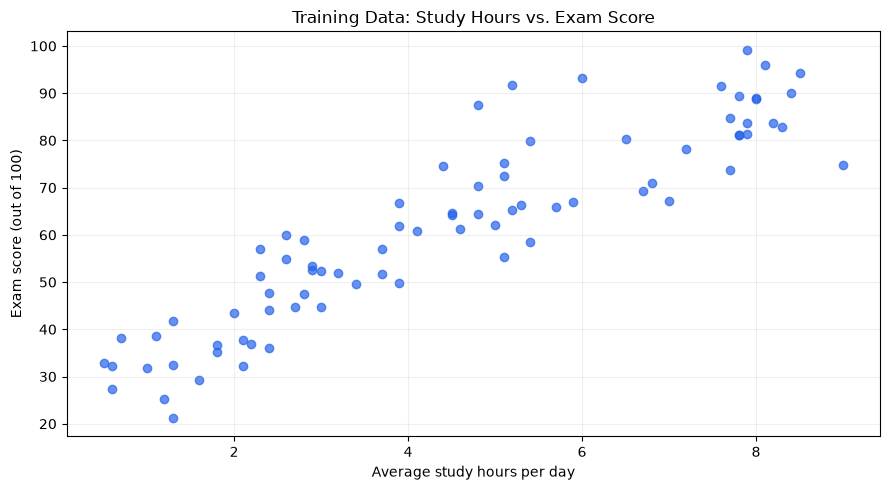

In [5]:
plt.scatter(X_train['study_hours'], y_train, alpha=0.7, color='#2563eb')
plt.title('Training Data: Study Hours vs. Exam Score')
plt.xlabel('Average study hours per day')
plt.ylabel('Exam score (out of 100)')
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

### 6. Train a linear regression model
6. 선형 회귀 모델 학습

The model learns a slope and an intercept.  
모델은 기울기와 절편을 학습합니다.

$$\hat{y} = w x + b$$

`x`: average daily study hours; `ŷ`: predicted exam score.  
`x`: 하루 평균 공부 시간, `ŷ`: 예측 시험 점수.

`w`: slope; `b`: intercept.  
`w`: 기울기, `b`: 절편.

Training minimizes the sum of squared errors between actual and predicted training scores.  
학습 과정은 학습 데이터의 실제 점수와 예측 점수 사이의 제곱 오차 합을 최소화합니다.

In [6]:
model = LinearRegression()
model.fit(X_train, y_train)
print(f'Predicted score = {model.coef_[0]:.2f} × hours + {model.intercept_:.2f}')
print(f'예측 점수 = {model.coef_[0]:.2f} × 공부 시간 + {model.intercept_:.2f}')

Predicted score = 7.44 × hours + 27.94
예측 점수 = 7.44 × 공부 시간 + 27.94


### 7. Evaluate on the test set
7. 테스트 데이터로 평가

**MAE:** Mean absolute error, measured in score points; lower is better.  
**MAE:** 평균 절대 오차로, 단위는 점이며 낮을수록 좋습니다.

**RMSE:** Root mean squared error, also in score points; it is more sensitive to large errors.  
**RMSE:** 평균 제곱근 오차로, 단위는 점이며 큰 오차에 더 민감합니다.

**R²:** The coefficient of determination; values closer to 1 are better, and negative values are possible.  
**R²:** 결정계수로, 1에 가까울수록 좋으며 음수가 될 수도 있습니다.

R² is not an accuracy percentage.  
R²는 정확도 백분율이 아닙니다.

Compare the model with a baseline that always predicts the mean training score.  
항상 학습 데이터의 평균 점수만 예측하는 기준 모델과 비교합니다.

In [7]:
y_pred = model.predict(X_test)
baseline_pred = np.full(len(y_test), y_train.mean())
def evaluate(actual, predicted):
    return {'MAE': mean_absolute_error(actual, predicted),
            'RMSE': np.sqrt(mean_squared_error(actual, predicted)),
            'R2': r2_score(actual, predicted)}
metrics = pd.DataFrame({
    'Linear regression': evaluate(y_test, y_pred),
    'Training-mean baseline': evaluate(y_test, baseline_pred)
}).T
display(metrics.round(3))
comparison = X_test.copy()
comparison['actual_score'] = y_test
comparison['predicted_score'] = y_pred
comparison['absolute_error'] = abs(y_test - y_pred)
display(comparison.sort_index().round(2))

,MAE,RMSE,R2
Linear regression,4.421,5.347,0.905
Training-mean baseline,15.047,17.340,-0.004


,study_hours,actual_score,predicted_score,absolute_error
0,5.9,76.8,71.86,4.94
4,4.1,63.5,58.46,5.04
10,7.3,79.1,82.29,3.19
12,8.6,88.6,91.97,3.37
18,7.5,72.3,83.78,11.48
22,1.2,38.7,36.87,1.83
30,8.9,86.6,94.20,7.60
31,6.3,67.2,74.84,7.64
33,0.8,30.6,33.90,3.30
39,2.6,49.6,47.30,2.30


### 8. Visualize the regression line and residuals
8. 회귀선과 잔차 시각화

The regression line summarizes the fitted relationship between study time and score.  
회귀선은 모델이 학습한 공부 시간과 점수 사이의 관계를 나타냅니다.

A residual is the actual score minus the predicted score.  
잔차는 실제 점수에서 예측 점수를 뺀 값입니다.

Residuals farther from zero indicate larger prediction errors.  
잔차가 0에서 멀수록 예측 오차가 큽니다.

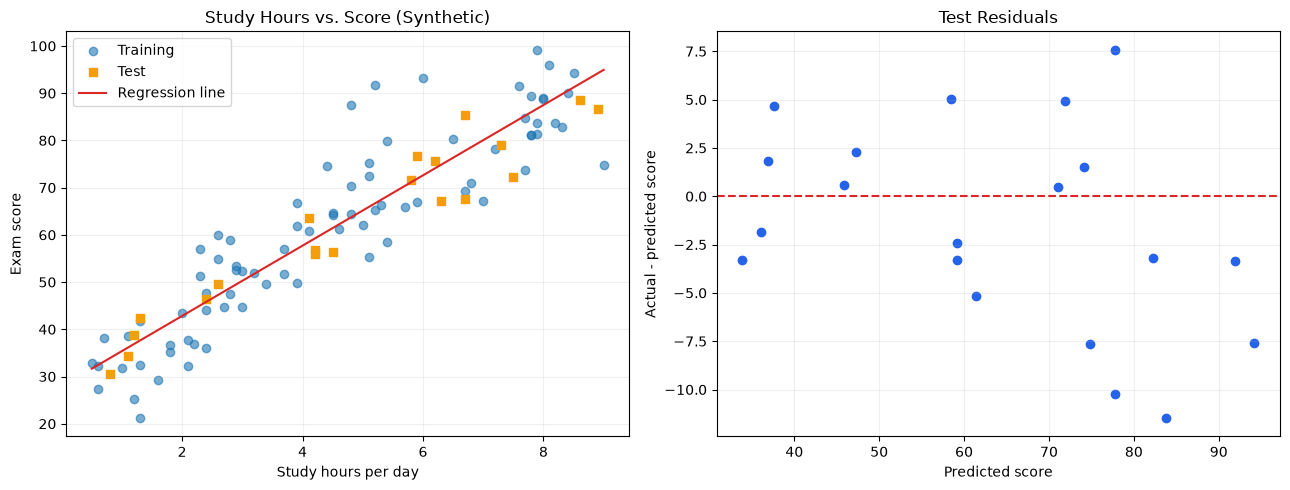

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].scatter(X_train['study_hours'], y_train, label='Training', alpha=0.6)
axes[0].scatter(X_test['study_hours'], y_test, label='Test', marker='s', color='#f59e0b')
line_X = pd.DataFrame({'study_hours': np.linspace(X.study_hours.min(), X.study_hours.max(), 100)})
axes[0].plot(line_X.study_hours, model.predict(line_X), color='#dc2626', label='Regression line')
axes[0].set(title='Study Hours vs. Score (Synthetic)', xlabel='Study hours per day', ylabel='Exam score')
axes[0].legend()
axes[1].scatter(y_pred, y_test - y_pred, color='#2563eb')
axes[1].axhline(0, color='#dc2626', linestyle='--')
axes[1].set(title='Test Residuals', xlabel='Predicted score', ylabel='Actual - predicted score')
for ax in axes:
    ax.grid(alpha=0.2)
fig.tight_layout()
plt.show()

### 9. Predict a new score
9. 새로운 점수 예측

Change `hours` and run the cell again to predict a score for another study time.  
`hours` 값을 바꾸고 셀을 다시 실행하면 다른 공부 시간에 대한 점수를 예측할 수 있습니다.

Predictions outside the training range may be unreliable.  
학습 범위를 벗어난 예측은 신뢰하기 어려울 수 있습니다.

Linear regression does not automatically keep predictions between 0 and 100.  
선형 회귀는 예측값을 자동으로 0~100 범위 안에 제한하지 않습니다.

In [9]:
hours = 5.0
if not np.isfinite(hours) or not 0 <= hours <= 24:
    raise ValueError('hours must be a finite number between 0 and 24.\n공부 시간은 0~24 사이의 유한한 숫자여야 합니다.')
score = model.predict(pd.DataFrame({'study_hours': [hours]}))[0]
print(f'Study hours per day: {hours:g}')
print(f'하루 평균 공부 시간: {hours:g}시간')
print(f'Predicted exam score: {score:.1f} / 100')
print(f'예측 시험 점수: {score:.1f} / 100점')
if not X_train.study_hours.min() <= hours <= X_train.study_hours.max():
    print('Warning: outside the training range (extrapolation).\n주의: 학습 범위를 벗어난 외삽 예측입니다.')
if not 0 <= score <= 100:
    print('Warning: prediction is outside the valid score range.\n주의: 예측값이 유효 점수 범위를 벗어났습니다.')

Study hours per day: 5
하루 평균 공부 시간: 5시간
Predicted exam score: 65.2 / 100
예측 시험 점수: 65.2 / 100점


### 10. Conclusion and limitations
10. 결론과 한계

The linear regression model achieved a test MAE of 4.42 points, compared with 15.05 points for the mean baseline.  
선형 회귀 모델의 테스트 MAE는 4.42점으로, 평균값 기준 모델의 15.05점보다 낮았습니다.

The test R² was 0.905, and the predicted score for five study hours per day was 65.2.  
테스트 R²는 0.905였으며, 하루 5시간 공부할 때 예측 점수는 65.2점이었습니다.

The slope describes how much the predicted score differs when study time differs by one hour.  
기울기는 공부 시간이 1시간 다를 때 예측 점수가 얼마나 달라지는지 나타냅니다.

It does not prove that studying one extra hour causes that increase in score.  
공부 시간을 1시간 늘리면 실제 점수가 그만큼 오른다는 인과관계를 증명하지는 않습니다.

**Limitations:** This small synthetic dataset was generated with a linear relationship and excludes sleep, prior knowledge, and exam difficulty.  
**한계:** 선형 관계를 넣어 만든 작은 가상 데이터이며, 수면·사전 지식·시험 난이도를 고려하지 않았습니다.

The results come from one train/test split and cannot be generalized to real students.  
한 번의 학습·테스트 분할에 따른 결과이므로 실제 학생에게 일반화할 수 없습니다.

**Next step:** Collect real data and compare a multiple linear regression model with additional features.  
**다음 단계:** 실제 자료를 수집하고 추가 변수를 사용하는 다중 선형 회귀 모델과 비교할 수 있습니다.

**Format reference:** [ANN Diabetes notebook by Md. Jalil Piran](https://github.com/jalil-piran/AI/blob/main/AI09_ANN_Diabetes.ipynb).  
**형식 참고:** [Md. Jalil Piran의 ANN Diabetes 실습 노트북](https://github.com/jalil-piran/AI/blob/main/AI09_ANN_Diabetes.ipynb).

Only the step-by-step presentation format was referenced; this project uses separately written analysis code and synthetic data.  
단계별 설명 형식만 참고했으며, 본 프로젝트는 별도로 작성한 분석 코드와 가상 데이터를 사용합니다.